# Recherche de stratégies sur les boosts

M affiche +217,52 € sur 22 paris réglés dans le replay, K +41,73 € sur 36. Ce sont des résultats exploratoires issus des règlements automatiques enregistrés. Le modèle ne bat pas le prior bookmaker au score global de Brier. Le suivi prospectif commence le 14 octobre 2026 à 00:00 UTC.

## Contexte et méthode

Historique reconstitué depuis 141 instantanés Git, source initiale `fb09dbd70b7d302838c1a107cc47e77db2a3bcdb`. Les caractéristiques proviennent du premier instantané avant match ; les résultats sont disponibles uniquement à la publication de leur commit. Après 30 résultats d’amorçage, le modèle apprend avec le seul passé.

Banque 1 000 €, mises ouvertes ≤ 10 %, exposition par libellé de rencontre ≤ 2 %. Les 56 filtres et les 9 variantes de mise ont été comparés après consultation de la même petite période. Les règlements ne sont pas vérifiés contre des résultats officiels.

Exécuter depuis la racine du dépôt ou le dossier `analyses`. Python 3.12 et Matplotlib suffisent aux calculs et aux figures ; Jupyter est nécessaire pour ouvrir ce fichier en mode interactif.

## Charger la source et rejouer les décisions

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'boosts').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from boosts.recherche_strategies import analyser
h = json.loads((ROOT / 'analyses/historique-strategies.json').read_text(encoding='utf-8'))
r = analyser(h)
print('Source initiale :', r['source_sha'])
print('Dernière observation :', r['derniere_observation'])
print('Qualité :', r['qualite'])


Source initiale : fb09dbd70b7d302838c1a107cc47e77db2a3bcdb
Dernière observation : 2026-10-13T20:20:32+00:00
Qualité : {'producteurs_verdicts': {'gpt-6-luna': 126}, 'observations_apres_debut': 1, 'mises_supposees': 2, 'methodes_value': {'approx': 27, 'exacte': 17}}


## Comparaison des stratégies et de leurs témoins

In [2]:
keys = ['temoin_10', 'temoin_20', 'J_adaptative', 'K_modele', 'L_kelly_dynamique', 'M_modele_20']
bilans = {**r['temoins'], **r['strategies']}
print(f"{'Simulation':23} {'Réglés':>7} {'Gain €':>10} {'ROI %':>8} {'Baisse €':>10}")
for key in keys:
    g = bilans[key]['global']
    print(f"{key:23} {g['regles']:7} {g['gain_net']:10.2f} {g['roi_pct']:8.1f} {g['pire_baisse']:10.2f}")


Simulation               Réglés     Gain €    ROI %   Baisse €
temoin_10                    46      12.56      2.8    -107.52
temoin_20                    27      49.27      9.9    -161.00
J_adaptative                 29     -68.10    -24.2    -122.83
K_modele                     36      41.73     12.1     -74.75
L_kelly_dynamique            39       9.28      4.0     -59.37
M_modele_20                  22     217.52     52.2     -85.88


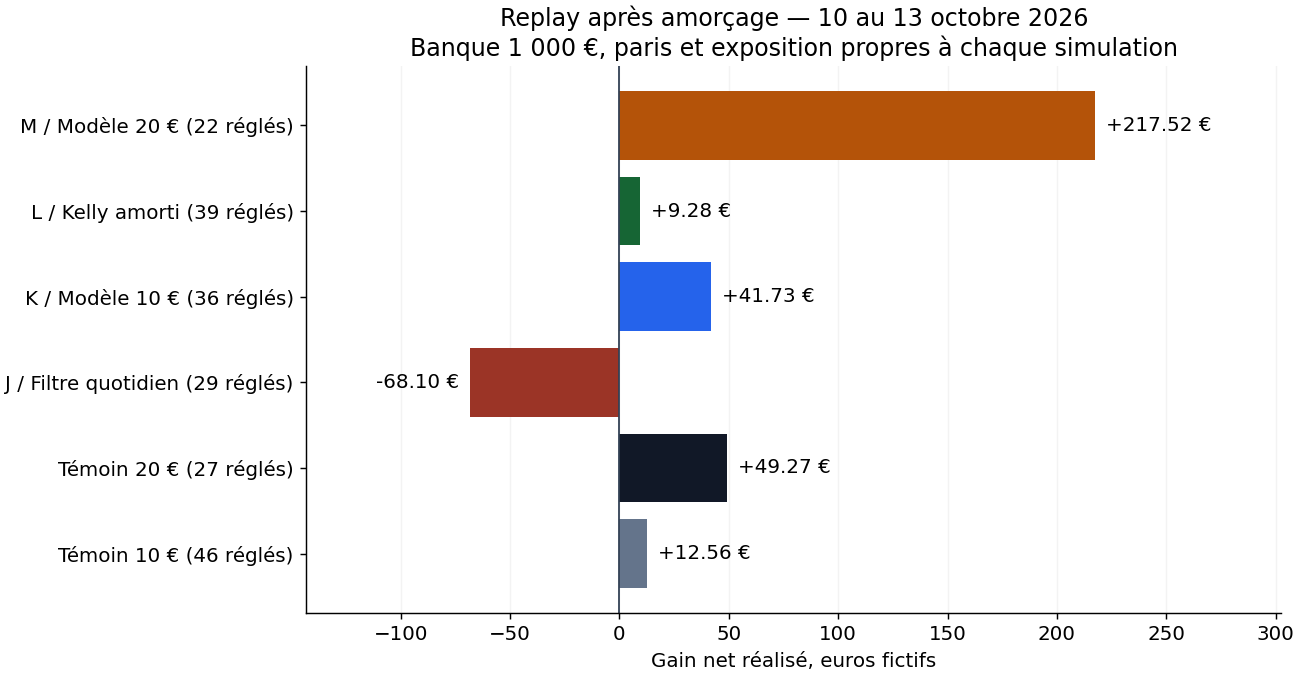

In [3]:
import os, tempfile
os.environ.setdefault('MPLCONFIGDIR', tempfile.mkdtemp(prefix='cotes-mpl-'))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
plt.rcParams.update({'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
gains = [bilans[k]['global']['gain_net'] for k in keys]
display_names = dict(zip(keys, ['Témoin 10 €', 'Témoin 20 €', 'J / Filtre quotidien', 'K / Modèle 10 €', 'L / Kelly amorti', 'M / Modèle 20 €']))
labels = [f"{display_names[k]} ({bilans[k]['global']['regles']} réglés)" for k in keys]
fig, ax = plt.subplots(figsize=(10,5.2), layout='constrained')
colors = ['#64748b', '#111827', '#9b3426', '#2563eb', '#166534', '#b45309']
ax.barh(labels, gains, color=colors)
ax.axvline(0, color='#334155', linewidth=1)
for i, value in enumerate(gains):
    ax.text(value + (5 if value >= 0 else -5), i, f'{value:+.2f} €',
            ha='left' if value >= 0 else 'right', va='center')
ax.set_xlim(min(gains)-75, max(gains)+85)
ax.set_xlabel('Gain net réalisé, euros fictifs')
ax.set_title('Replay après amorçage — 10 au 13 octobre 2026\nBanque 1 000 €, paris et exposition propres à chaque simulation')
ax.grid(axis='x', alpha=0.15)
ax.set_axisbelow(True)
plt.show()


M immobilise davantage d’argent par pari et joue moins d’offres. Son résultat ne se déduit pas en doublant celui de K. Les témoins utilisent les mêmes montants et plafonds d’exposition.

## Gain cumulé au moment où les règlements deviennent connus

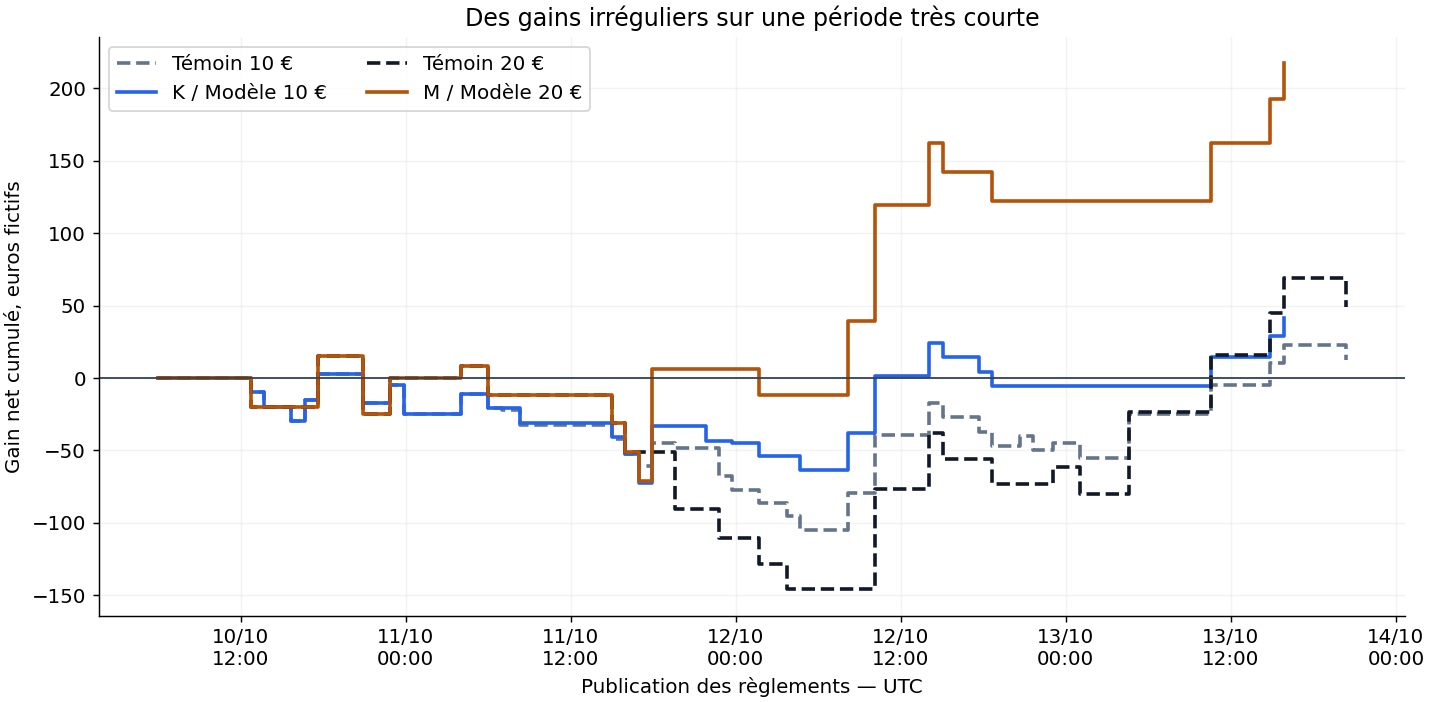

In [4]:
fig, ax = plt.subplots(figsize=(11,5.4), layout='constrained')
for key, color, style in [('temoin_10','#64748b','--'), ('K_modele','#2563eb','-'),
                         ('temoin_20','#111827','--'), ('M_modele_20','#b45309','-')]:
    b = bilans[key]
    xs = [datetime.fromisoformat(b['replay']['debut_evaluation'])] + [datetime.fromisoformat(p['debut']) for p in b['courbe']]
    ys = [0] + [p['cumul'] for p in b['courbe']]
    ax.step(xs, ys, where='post', label=display_names[key], color=color, linestyle=style, linewidth=2)
ax.axhline(0, color='#334155', linewidth=1)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m\n%H:%M'))
ax.set_xlabel('Publication des règlements — UTC')
ax.set_ylabel('Gain net cumulé, euros fictifs')
ax.set_title('Des gains irréguliers sur une période très courte')
ax.grid(alpha=0.15)
ax.legend(ncol=2, loc='upper left')
plt.show()


## Calibration et dispersion

In [5]:
print('Score de Brier, plus bas = meilleur :', r['strategies']['K_modele']['replay']['calibration'])
for key in r['strategies']:
    print(key, 'dispersion ROI 90 % par rencontres :', r['strategies'][key]['replay']['dispersion_roi_90_pct'])
print('Les intervalles ne corrigent pas le choix des méthodes après lecture des données.')


Score de Brier, plus bas = meilleur : {'predictions_reglees': 88, 'brier_modele': 0.2179, 'brier_prior_bookmaker': 0.2147}
J_adaptative dispersion ROI 90 % par rencontres : [-62.8, 17.3]
K_modele dispersion ROI 90 % par rencontres : [-29.8, 55.7]
L_kelly_dynamique dispersion ROI 90 % par rencontres : [-35.6, 47.5]
M_modele_20 dispersion ROI 90 % par rencontres : [-10.3, 115.9]
Les intervalles ne corrigent pas le choix des méthodes après lecture des données.


## Interprétation

K et M donnent des pistes de sélection et de gestion du capital à tester prospectivement. La stratégie J qui poursuit les meilleurs filtres historiques perd sur ce replay. L réduit le montant des mises mais ne maximise pas les gains.

La performance reste sensible à un petit nombre de paris de tennis, à la fiabilité des verdicts automatiques, à l’exposition simultanée et à la période. Le score de Brier du modèle est légèrement moins bon que celui du prior bookmaker : il serait injustifié d’affirmer que les probabilités sont validées. Le rapport `RECHERCHE.md` présente tous les filtres, la sensibilité des mises et les résultats par jour et sport.